In [3]:
import numpy as np 
import pandas as pd


In [4]:
d=pd.read_csv("ecommerce_dataset.csv")
print(d)

       User_ID  Product_ID        Category  Price (Rs.)  Discount (%)  \
0     337c166f  f414122f-e          Sports        36.53            15   
1     d38a19bf  fde50f9c-5        Clothing       232.79            20   
2     d7f5f0b0  0d96fc90-3          Sports       317.02            25   
3     395d4994  964fc44b-d            Toys       173.19            25   
4     a83c145c  d70e2fc6-e          Beauty       244.80            20   
...        ...         ...             ...          ...           ...   
3655  67abda0a  28714133-6          Beauty       486.79             0   
3656  34ebc1a0  08838c2c-9            Toys       212.87            15   
3657  1defd3b1  c39a4f16-6  Home & Kitchen       389.76             0   
3658  0611293d  b4f67f96-9     Electronics       447.66            30   
3659  e73ad07c  a5d07442-d  Home & Kitchen       235.77            30   

      Final_Price(Rs.)    Payment_Method Purchase_Date  
0                31.05       Net Banking    12-11-2024  
1        

In [5]:
print(d.head())

    User_ID  Product_ID  Category  Price (Rs.)  Discount (%)  \
0  337c166f  f414122f-e    Sports        36.53            15   
1  d38a19bf  fde50f9c-5  Clothing       232.79            20   
2  d7f5f0b0  0d96fc90-3    Sports       317.02            25   
3  395d4994  964fc44b-d      Toys       173.19            25   
4  a83c145c  d70e2fc6-e    Beauty       244.80            20   

   Final_Price(Rs.) Payment_Method Purchase_Date  
0             31.05    Net Banking    12-11-2024  
1            186.23    Net Banking    09-02-2024  
2            237.76    Credit Card    01-09-2024  
3            129.89            UPI    01-04-2024  
4            195.84    Net Banking    27-09-2024  


In [6]:
print(d.tail())

       User_ID  Product_ID        Category  Price (Rs.)  Discount (%)  \
3655  67abda0a  28714133-6          Beauty       486.79             0   
3656  34ebc1a0  08838c2c-9            Toys       212.87            15   
3657  1defd3b1  c39a4f16-6  Home & Kitchen       389.76             0   
3658  0611293d  b4f67f96-9     Electronics       447.66            30   
3659  e73ad07c  a5d07442-d  Home & Kitchen       235.77            30   

      Final_Price(Rs.)    Payment_Method Purchase_Date  
3655            486.79               UPI    14-05-2024  
3656            180.94  Cash on Delivery    19-11-2024  
3657            389.76       Net Banking    07-08-2024  
3658            313.36               UPI    21-05-2024  
3659            165.04               UPI    14-04-2024  


In [7]:
print(d.describe())

       Price (Rs.)  Discount (%)  Final_Price(Rs.)
count  3660.000000   3660.000000       3660.000000
mean    254.800675     18.825137        206.906579
std     141.682621     14.731338        122.687844
min      10.090000      0.000000          5.890000
25%     134.012500      5.000000        104.512500
50%     253.845000     15.000000        199.185000
75%     377.595000     25.000000        304.117500
max     499.960000     50.000000        496.820000


In [8]:
print(d.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3660 entries, 0 to 3659
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           3660 non-null   object 
 1   Product_ID        3660 non-null   object 
 2   Category          3660 non-null   object 
 3   Price (Rs.)       3660 non-null   float64
 4   Discount (%)      3660 non-null   int64  
 5   Final_Price(Rs.)  3660 non-null   float64
 6   Payment_Method    3660 non-null   object 
 7   Purchase_Date     3660 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 228.9+ KB
None


In [9]:
print(d.isnull())

      User_ID  Product_ID  Category  Price (Rs.)  Discount (%)  \
0       False       False     False        False         False   
1       False       False     False        False         False   
2       False       False     False        False         False   
3       False       False     False        False         False   
4       False       False     False        False         False   
...       ...         ...       ...          ...           ...   
3655    False       False     False        False         False   
3656    False       False     False        False         False   
3657    False       False     False        False         False   
3658    False       False     False        False         False   
3659    False       False     False        False         False   

      Final_Price(Rs.)  Payment_Method  Purchase_Date  
0                False           False          False  
1                False           False          False  
2                False           False 

In [10]:
print(d.isnull().sum())

User_ID             0
Product_ID          0
Category            0
Price (Rs.)         0
Discount (%)        0
Final_Price(Rs.)    0
Payment_Method      0
Purchase_Date       0
dtype: int64


In [11]:
print(d.duplicated().sum())

0


In [12]:
x = d[["Price (Rs.)", "Discount (%)"]]
y = d["Final_Price(Rs.)"]


In [13]:
print(x)

      Price (Rs.)  Discount (%)
0           36.53            15
1          232.79            20
2          317.02            25
3          173.19            25
4          244.80            20
...           ...           ...
3655       486.79             0
3656       212.87            15
3657       389.76             0
3658       447.66            30
3659       235.77            30

[3660 rows x 2 columns]


In [14]:
print(y)

0        31.05
1       186.23
2       237.76
3       129.89
4       195.84
         ...  
3655    486.79
3656    180.94
3657    389.76
3658    313.36
3659    165.04
Name: Final_Price(Rs.), Length: 3660, dtype: float64


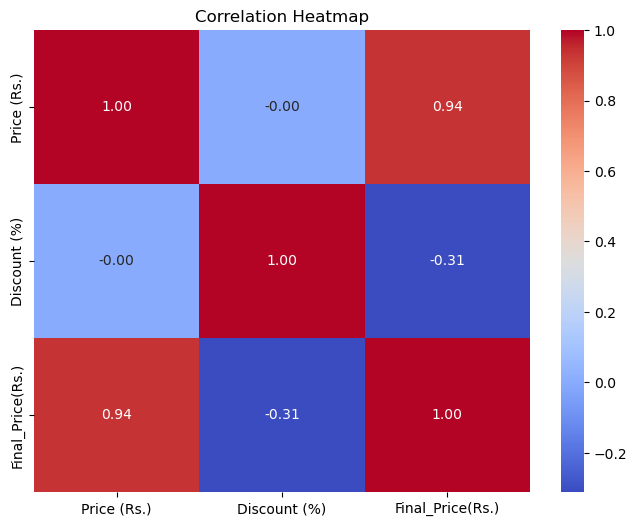

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = d.select_dtypes(include="number")
numeric_df = numeric_df.drop(columns=["User_ID", "Product_ID"], errors="ignore")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [17]:
print(x_train.head())

      Price (Rs.)  Discount (%)
1966       144.04             0
570        133.61            10
3388       429.90            25
343         44.29             0
3408       187.71            10


In [18]:
print(y_train.head())

1966    144.04
570     120.25
3388    322.42
343      44.29
3408    168.94
Name: Final_Price(Rs.), dtype: float64


In [19]:
print(x_test.head())

      Price (Rs.)  Discount (%)
291        374.32            50
270         69.77             5
149        185.46            10
1188       362.57             5
2037       426.71            50


In [20]:
print(y_test.head())

291     187.16
270      66.28
149     166.91
1188    344.44
2037    213.35
Name: Final_Price(Rs.), dtype: float64


In [21]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
y_pred = model.predict(x_test)
print("Predicted values:")
print(y_pred)

Predicted values:
[ 2.24176480e+02  9.14354246e+01  1.72938716e+02  3.30230651e+02
  2.66903536e+02  2.37226700e+02  3.93778889e+02  2.74843733e+02
  1.70872944e+02  3.15778973e+02  3.25640174e+02  3.59213500e+01
  2.12428008e+02  2.01438927e+02  2.12372030e+02 -5.67015116e+01
  3.46516034e+02  2.78150074e+02  2.00801681e+02  5.53201288e+01
  3.72624440e+02  3.80599480e+02 -4.78445575e+01  1.71971725e+02
  3.26643121e+02  2.70811356e+02  2.95158905e+01  2.45991720e+02
  1.34738004e+02  5.30072790e+01  2.96605217e+02  1.88255996e+02
  7.84028162e+01  3.16710931e+02  3.25876686e+02  1.39643207e+01
  7.92545182e+01  9.05907670e+01  2.26305274e+02  3.28047180e+02
  2.27645200e+02  1.97082739e+02  3.93844134e+02  1.79316375e+02
  1.28197233e+02  2.98661344e+02  3.80670470e+02  3.42136490e+02
  2.03594410e+02  2.60096231e+02  1.53806849e+02  3.71709904e+02
  1.33483157e+02  3.00250584e+01  3.44207243e+01  5.52304175e+01
  8.84143397e+01 -1.65760842e+01  1.60257908e+02  2.33822303e+02
  2.389

In [23]:
from sklearn.metrics import mean_absolute_error, r2_score
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 15.14203985254436
R2 Score: 0.9648438931112711


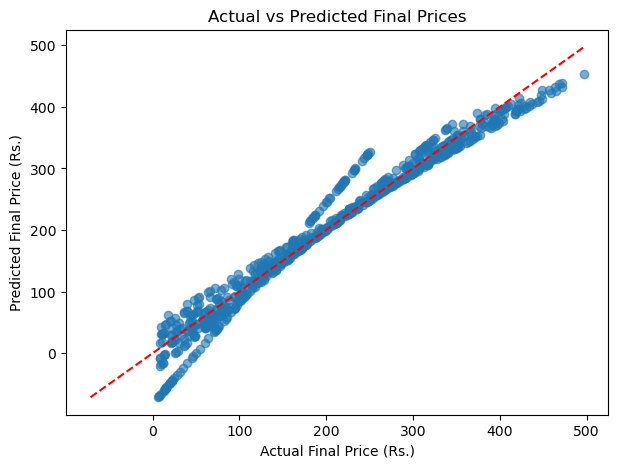

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")

plt.xlabel("Actual Final Price (Rs.)")
plt.ylabel("Predicted Final Price (Rs.)")
plt.title("Actual vs Predicted Final Prices")
plt.show()

In [47]:
result = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0        187.16       224.176480
1         66.28        91.435425
2        166.91       172.938716
3        344.44       330.230651
4        213.35       266.903536
5        233.66       237.226700
6        418.47       393.778889
7        273.54       274.843733
8        172.64       170.872944
9        327.61       315.778973


In [25]:
import joblib

joblib.dump(model, 'evebatch.pkl')

['evebatch.pkl']

In [27]:
import joblib

# Load the model from the file
loaded_model = joblib.load('evebatch.pkl')

# Make predictions with the loaded model
y_pred = loaded_model.predict([[82,96]])
print(y_pred)


[-132.43396024]


C:\Users\acer\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
